# UTS IS794 — Audit Dataset dan EDA

Vassel Goleyu / 00000138850. Analisis atas 229 foto milik sendiri, seluruhnya berlabel; asal foto adalah pernyataan pemilik, tanpa bukti metadata kamera. Statistik citra hanya memakai training. Tidak menjalankan training atau prediksi test.

In [1]:
from pathlib import Path
import sys, json, io, contextlib
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "scripts/uts_audit.py").exists())
sys.path.insert(0, str(ROOT))
from scripts.uts_audit import run
with contextlib.redirect_stdout(io.StringIO()):
    summary = run()
print(json.dumps(summary, ensure_ascii=False, indent=2))

{
  "source_files": 233,
  "unique_source_bytes": 229,
  "duplicate_excess": 4,
  "corrupt": 0,
  "inventory_files": 490,
  "label_counts": {
    "segar": 91,
    "tidak_segar": 69,
    "busuk": 69
  },
  "split_counts": {
    "train": 193,
    "val": 30,
    "test": 6
  },
  "groups": 61,
  "primary_verified": true,
  "provenance_basis": "owner_attestation",
  "canonical_unique_images": 229,
  "pending_label_images": 0,
  "visually_reviewed_images": 22,
  "physical_ground_truth_verified": false,
  "crossing_metadata_keys": [],
  "near_train_pairs": 8,
  "manifest_near_pairs": 5,
  "manifest_near_cross_split": 0,
  "dimensions": [
    {
      "format": "JPEG",
      "width": 1200,
      "height": 1600,
      "n": 22
    },
    {
      "format": "PNG",
      "width": 1254,
      "height": 1254,
      "n": 207
    }
  ],
  "training_medians": {
    "brightness": {
      "busuk": 0.5056895155364391,
      "segar": 0.5217326069750817,
      "tidak_segar": 0.48792623524385337
    },
    "sa

## Statistik aktual
Statistik citra hanya memakai training (217 foto). Audit file sumber mencakup data/raw, data/reference_import, dan submission/dataset/images; salinan paket/demo dicatat terpisah.

In [2]:
import pandas as pd
from IPython.display import display, Image
OUT = ROOT / "submission/uts"
display(pd.read_csv(OUT / "descriptive_training.csv", index_col=0))
metrics = pd.read_csv(OUT / "training_metrics.csv")
display(metrics.groupby("label")[["brightness", "saturation", "edge"]].agg(["count", "mean", "std", "min", "median", "max"]))
print("Pasangan dekat training:")
pairs = pd.read_csv(OUT / "training_dhash_pairs.csv")
display(pairs[pairs.distance.le(4)])

Pasangan dekat training:


,brightness,saturation,edge,red_mean,green_mean,blue_mean
count,193.000000,193.000000,193.000000,193.000000,193.000000,193.000000
mean,0.494391,0.394552,0.021749,0.601931,0.459344,0.392796
std,0.075787,0.107662,0.006880,0.084669,0.079388,0.091836
min,0.283588,0.157563,0.007713,0.348674,0.225699,0.125053
25%,0.451458,0.328484,0.017234,0.577626,0.408799,0.323248
50%,0.507086,0.398510,0.020994,0.629150,0.473442,0.392825
75%,0.547644,0.466867,0.025321,0.655794,0.517503,0.462650
max,0.662995,0.705191,0.048181,0.744344,0.645703,0.623316


brightness                      ...      edge                    
                 count      mean       std  ...       min    median       max
label                                       ...                              
busuk               57  0.491629  0.078282  ...  0.010199  0.021901  0.048181
segar               79  0.501591  0.072187  ...  0.007713  0.020749  0.039740
tidak_segar         57  0.487173  0.078566  ...  0.009988  0.020441  0.040651

[3 rows x 18 columns]

,a,b,distance,same_group,same_label
6599,data/raw/TOM042_tidak_segar.png,data/raw/TOM052_busuk.png,4,True,False
9349,data/raw/own_067_segar.png,data/raw/own_069_busuk.png,4,True,False
18411,data/raw/tomat_ref_07.jpeg,data/raw/tomat_ref_11.jpeg,1,True,True
18437,data/raw/tomat_ref_09.jpeg,data/raw/tomat_ref_10.jpeg,3,True,True
18439,data/raw/tomat_ref_09.jpeg,data/raw/tomat_ref_12.jpeg,4,True,True
18451,data/raw/tomat_ref_10.jpeg,data/raw/tomat_ref_12.jpeg,3,True,True
18512,data/raw/tomat_ref_16.jpeg,data/raw/tomat_ref_22.jpeg,4,True,True
18516,data/raw/tomat_ref_17.jpeg,data/raw/tomat_ref_21.jpeg,3,True,True


### Gambar 1 — Distribusi kelas dan status label

Interpretasi lengkap ada di laporan PDF (bagian 3.2); notebook ini hanya memuat kode dan keluaran aktual.

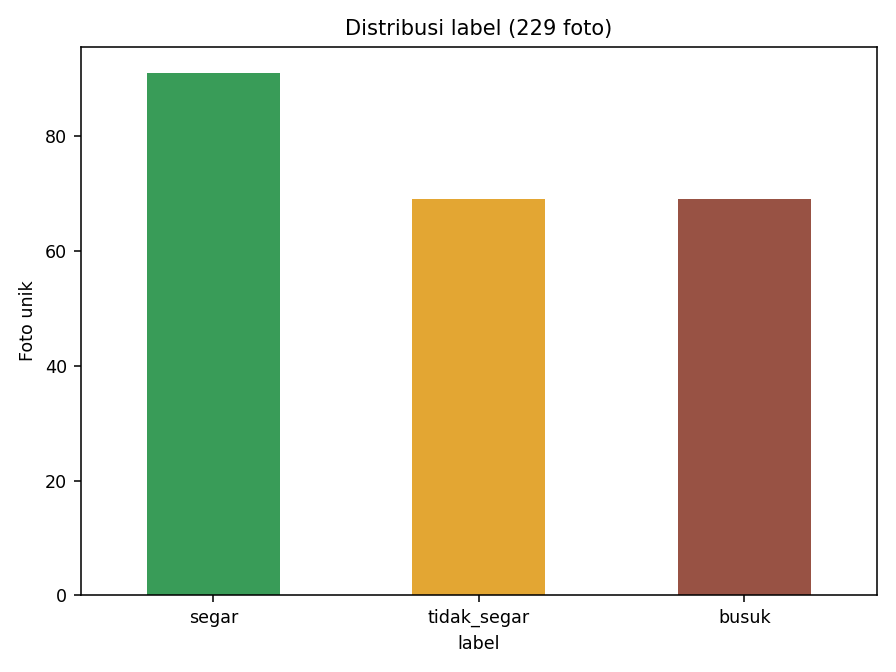

In [3]:
display(Image(filename=str(OUT / "figures/01.png")))

### Gambar 2 — Label per kelompok grup

Interpretasi lengkap ada di laporan PDF (bagian 3.2); notebook ini hanya memuat kode dan keluaran aktual.

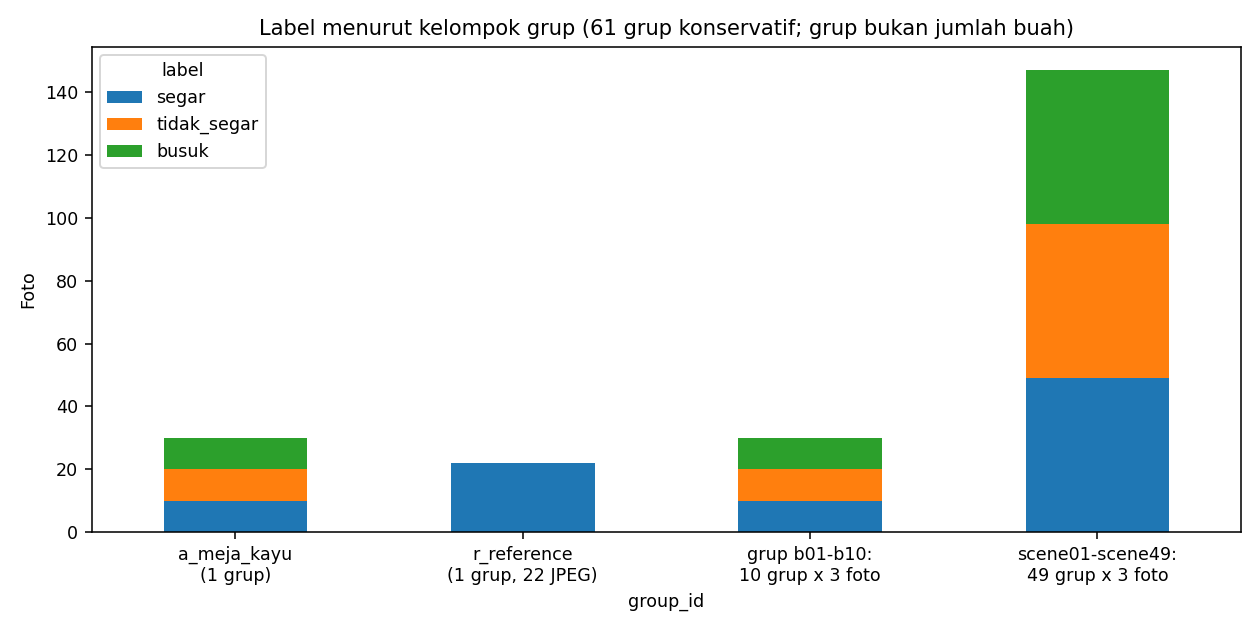

In [4]:
display(Image(filename=str(OUT / "figures/02.png")))

### Gambar 3 — Komposisi split

Interpretasi lengkap ada di laporan PDF (bagian 3.2); notebook ini hanya memuat kode dan keluaran aktual.

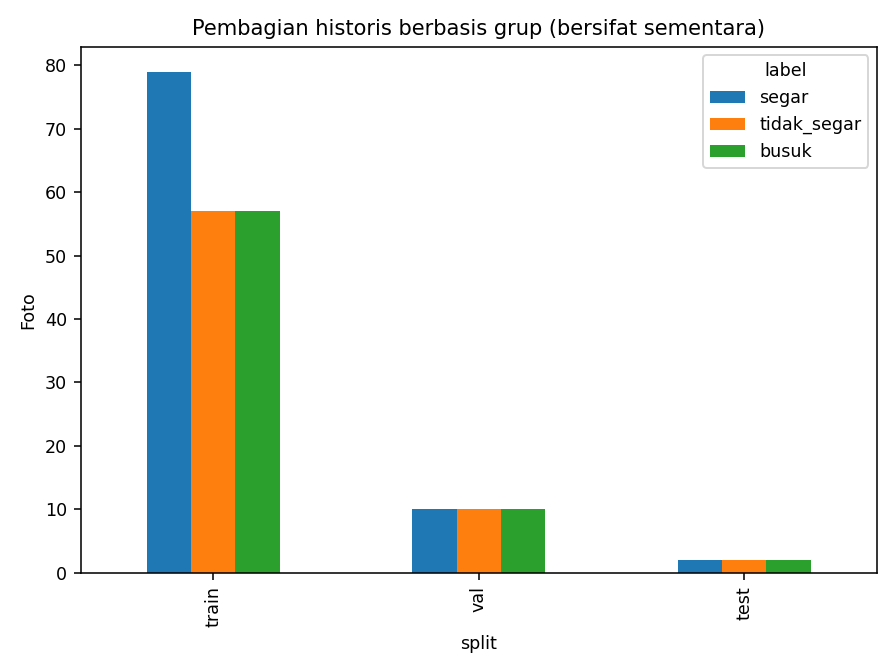

In [5]:
display(Image(filename=str(OUT / "figures/03.png")))

### Gambar 4 — Dimensi gambar dan format

Interpretasi lengkap ada di laporan PDF (bagian 3.2); notebook ini hanya memuat kode dan keluaran aktual.

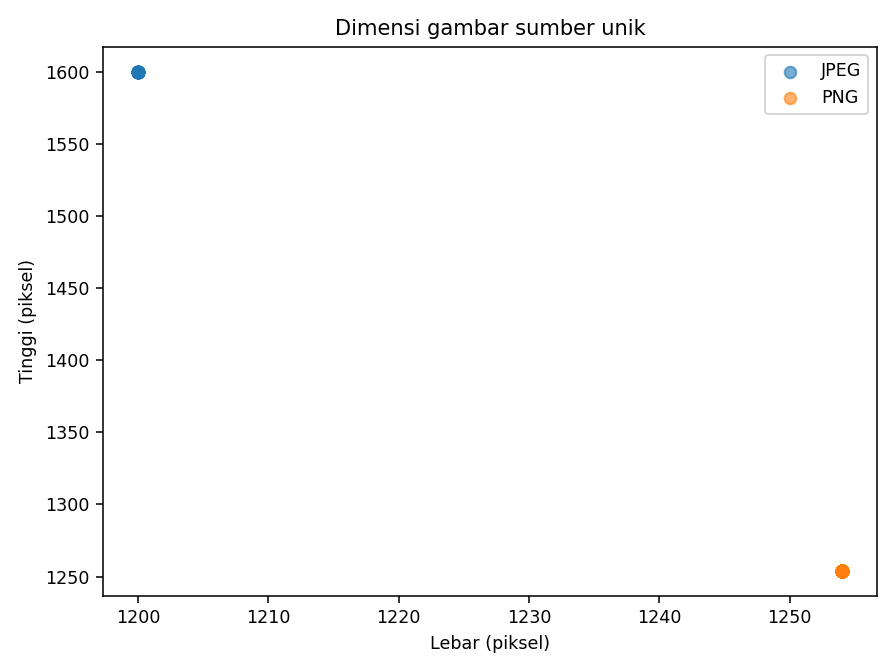

In [6]:
display(Image(filename=str(OUT / "figures/04.png")))

### Gambar 5 — Contoh per kelas

Interpretasi lengkap ada di laporan PDF (bagian 3.2); notebook ini hanya memuat kode dan keluaran aktual.

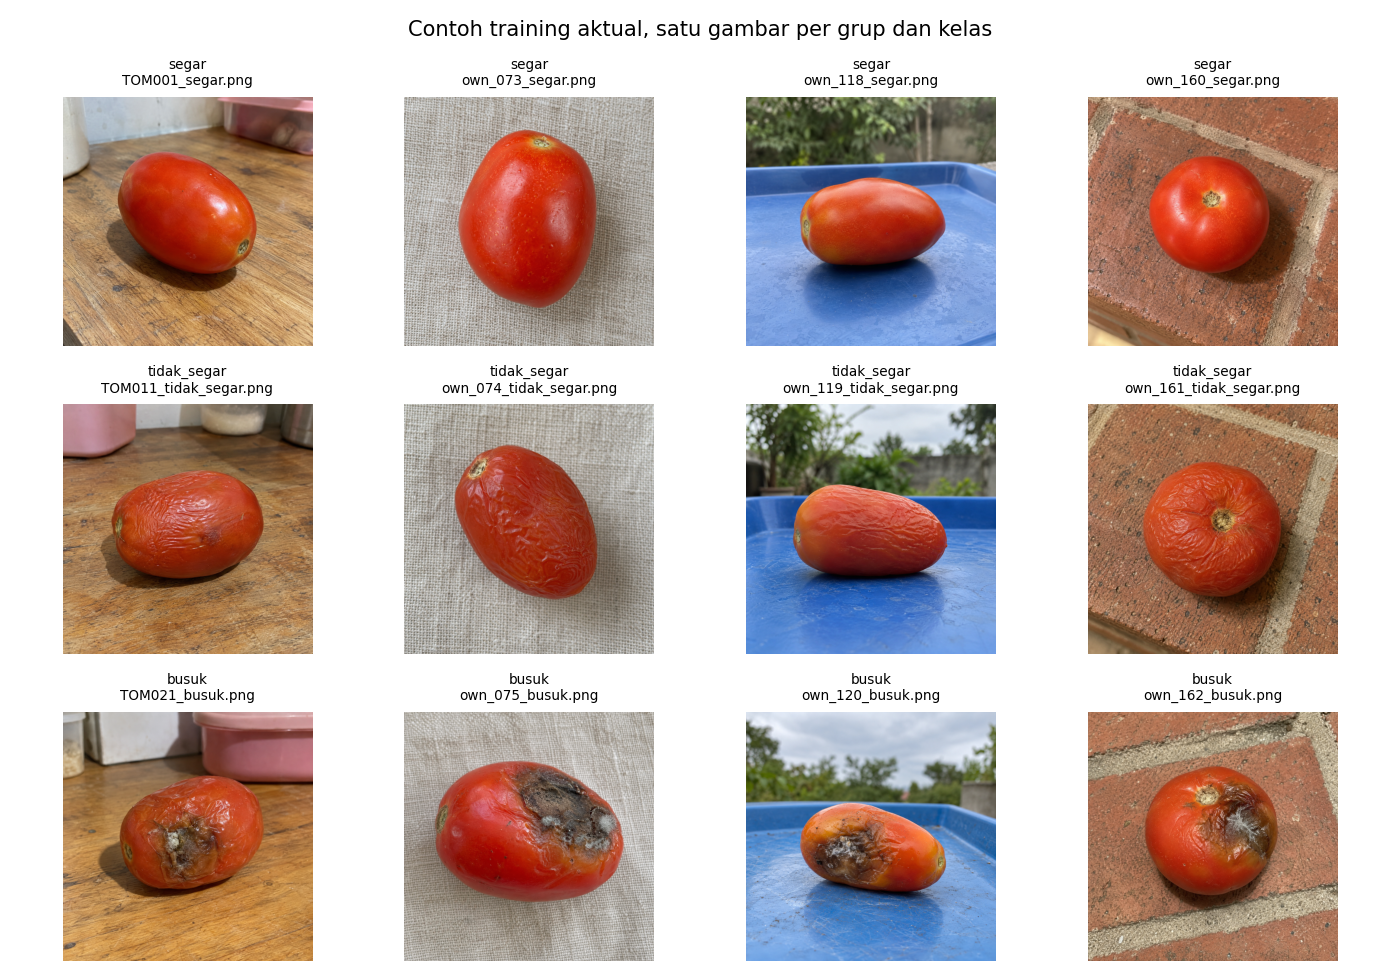

In [7]:
display(Image(filename=str(OUT / "figures/05.png")))

### Gambar 6 — Luminans (training)

Interpretasi lengkap ada di laporan PDF (bagian 3.2); notebook ini hanya memuat kode dan keluaran aktual.

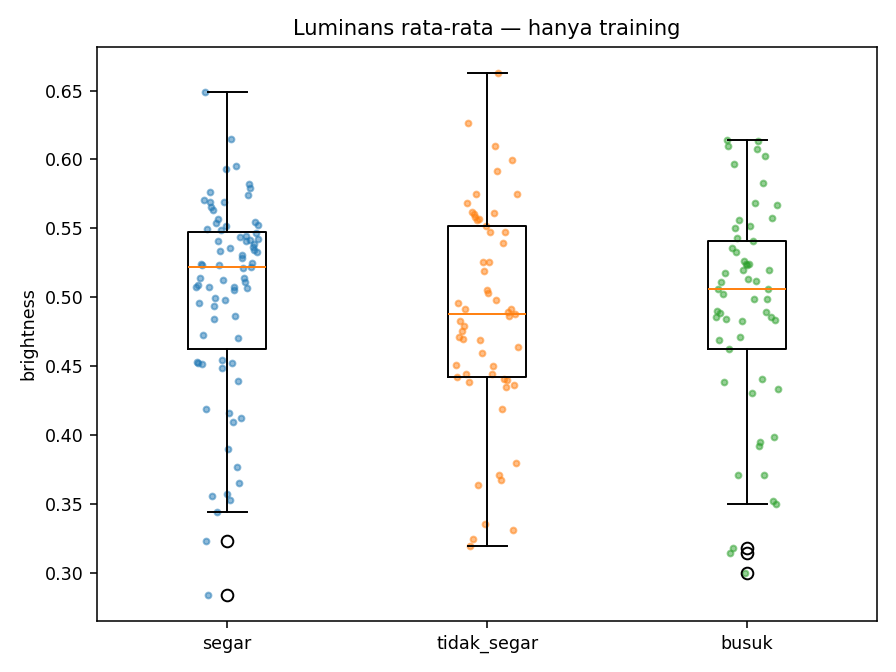

In [8]:
display(Image(filename=str(OUT / "figures/06.png")))

### Gambar 7 — Saturasi (training)

Interpretasi lengkap ada di laporan PDF (bagian 3.2); notebook ini hanya memuat kode dan keluaran aktual.

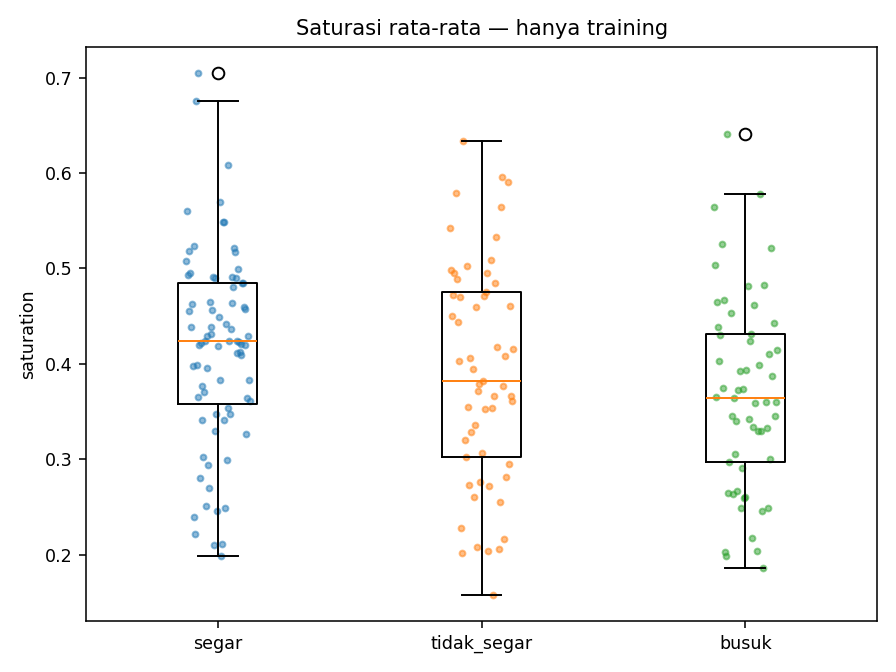

In [9]:
display(Image(filename=str(OUT / "figures/07.png")))

### Gambar 8 — Gradien (training)

Interpretasi lengkap ada di laporan PDF (bagian 3.2); notebook ini hanya memuat kode dan keluaran aktual.

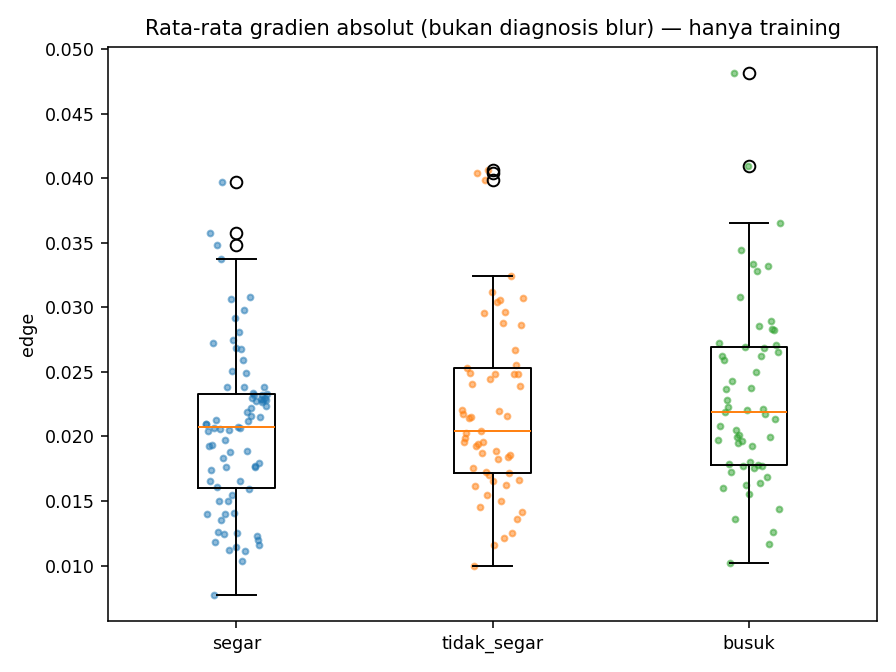

In [10]:
display(Image(filename=str(OUT / "figures/08.png")))

### Gambar 9 — Korelasi deskriptor

Interpretasi lengkap ada di laporan PDF (bagian 3.2); notebook ini hanya memuat kode dan keluaran aktual.

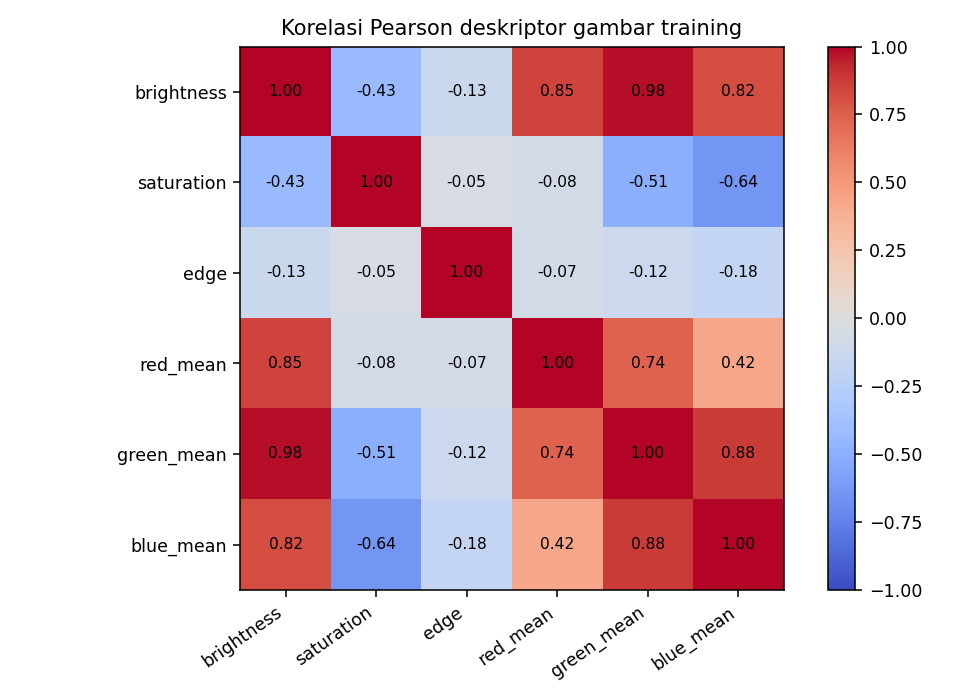

In [11]:
display(Image(filename=str(OUT / "figures/09.png")))

### Gambar 10 — Kemiripan visual (dHash)

Interpretasi lengkap ada di laporan PDF (bagian 3.2); notebook ini hanya memuat kode dan keluaran aktual.

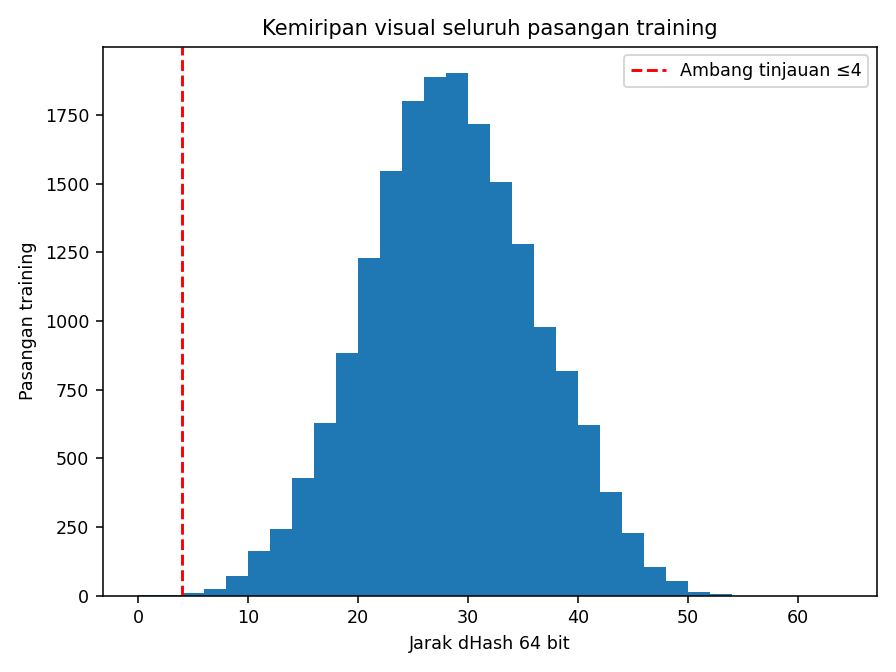

In [12]:
display(Image(filename=str(OUT / "figures/10.png")))

## Verifikasi dataset bersih
Bersih secara teknis tidak sama dengan label terverifikasi fisik.

In [13]:
import numpy as np
data = np.load(OUT / "clean_dataset_128.npz", allow_pickle=False)
manifest = pd.read_csv(OUT / "clean_manifest.csv")
assert len(manifest) == len(data["images"]) == 229
assert data["images"].shape == (229, 128, 128, 3)
assert np.isfinite(data["images"]).all()
assert data["images"].dtype == np.float32
assert np.all((data["images"] >= 0) & (data["images"] <= 1))
assert np.array_equal(data["labels"], manifest.label_idx.to_numpy())
assert np.array_equal(data["splits"], manifest.split.to_numpy())
assert manifest.groupby("group_id").split.nunique().max() == 1
print("Verifikasi tensor, label, split, dan grup: lulus; 229 foto milik sendiri; asal foto adalah pernyataan pemilik.")

Verifikasi tensor, label, split, dan grup: lulus; 229 foto milik sendiri; asal foto adalah pernyataan pemilik.
